## RT-DETR

In [1]:
import os, sys, subprocess, urllib.request
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
import os, sys, subprocess, urllib.request
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"
# Clona el repo oficial de RT-DETR si no existe y lo añade al path.

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))


In [2]:
from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}  # 0..79
DEVICE = "cpu"

# Mostramos las clases. Como se puede ver, son las mismas que las de YOLO.

print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [3]:
from load_rtdetr import load_rtdetr
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

Cargando RT-DETR familia 'v2', tamaño 'l' en cpu
Load PResNet50 state_dict


In [4]:
@torch.no_grad()
def detect(bgr, conf=0.6):
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

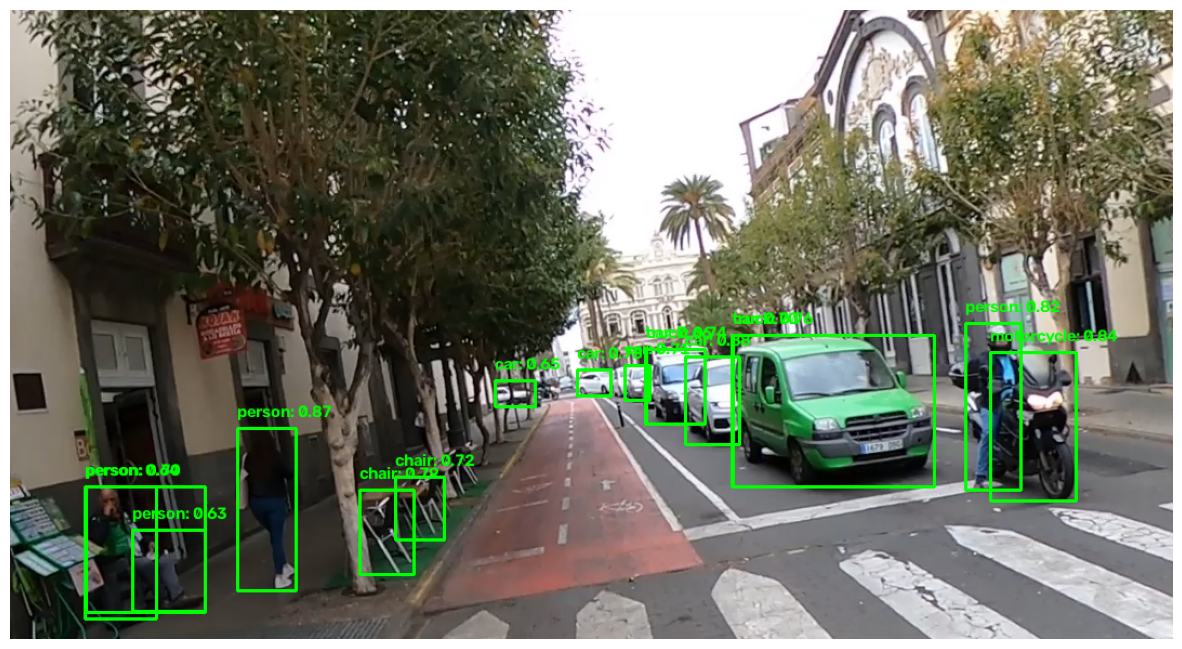

In [5]:

# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'

image = cv2.imread(path_test)

boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')